In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load our cleaned UPI dataset

df = pd.read_csv(
    "../data/processed/upi_2024_2026.csv"
)

# Convert Month into datetime format

df["Month"] = pd.to_datetime(df["Month"])

# Sort data chronologically

df = df.sort_values("Month").reset_index(drop=True)

# Display first five records

df.head()

,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Volume Growth (%),Value Growth (%),Average Transaction Value (₹)
0,2024-04-01,583,13303.99,1964464.52,NaN,NaN,1476.598013
1,2024-05-01,598,14035.84,2044937.05,5.500981,4.096410,1456.939556
2,2024-06-01,602,13885.14,2007081.20,-1.073680,-1.851199,1445.488630
3,2024-07-01,605,14435.55,2064292.41,3.964022,2.850468,1430.006068
4,2024-08-01,608,14963.05,2060735.57,3.654173,-0.172303,1377.216256


In [2]:
# Check dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDate Range:")
print(df["Month"].min(), "to", df["Month"].max())

Dataset Shape: (24, 7)

Column Names:
['Month', 'No. of Banks live on UPI', 'Volume (In Mn.)', 'Value (In Cr.)', 'Volume Growth (%)', 'Value Growth (%)', 'Average Transaction Value (₹)']

Missing Values:
Month                            0
No. of Banks live on UPI         0
Volume (In Mn.)                  0
Value (In Cr.)                   0
Volume Growth (%)                1
Value Growth (%)                 1
Average Transaction Value (₹)    0
dtype: int64

Date Range:
2024-04-01 00:00:00 to 2026-03-01 00:00:00


In [3]:
# Create a numerical time feature

df["Month_Number"] = np.arange(len(df))

# Select input and target variables

X = df[["Month_Number"]]

y = df["Volume (In Mn.)"]

# Split chronologically: first 21 months for training,
# final 3 months for testing

X_train = X.iloc[:21]
X_test = X.iloc[21:]

y_train = y.iloc[:21]
y_test = y.iloc[21:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 21
Testing records: 3


In [4]:
# Import Linear Regression

from sklearn.linear_model import LinearRegression

# Create the model

model = LinearRegression()

# Train the model

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [5]:
# Predict transaction volume for the test period

y_pred = model.predict(X_test)

# Compare actual and predicted values

results = pd.DataFrame({
    "Month": df["Month"].iloc[21:],
    "Actual Volume": y_test.values,
    "Predicted Volume": y_pred
})

results

,Month,Actual Volume,Predicted Volume
21,2026-01-01,21703.44,21630.100905
22,2026-02-01,20394.18,22026.152632
23,2026-03-01,22641.11,22422.204359


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

mape = np.mean(np.abs((y_test.values - y_pred) / y_test.values)) * 100

print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("Mean Absolute Percentage Error:", round(mape, 2), "%")

Mean Absolute Error: 641.41
Root Mean Squared Error: 951.6
Mean Absolute Percentage Error: 3.1 %


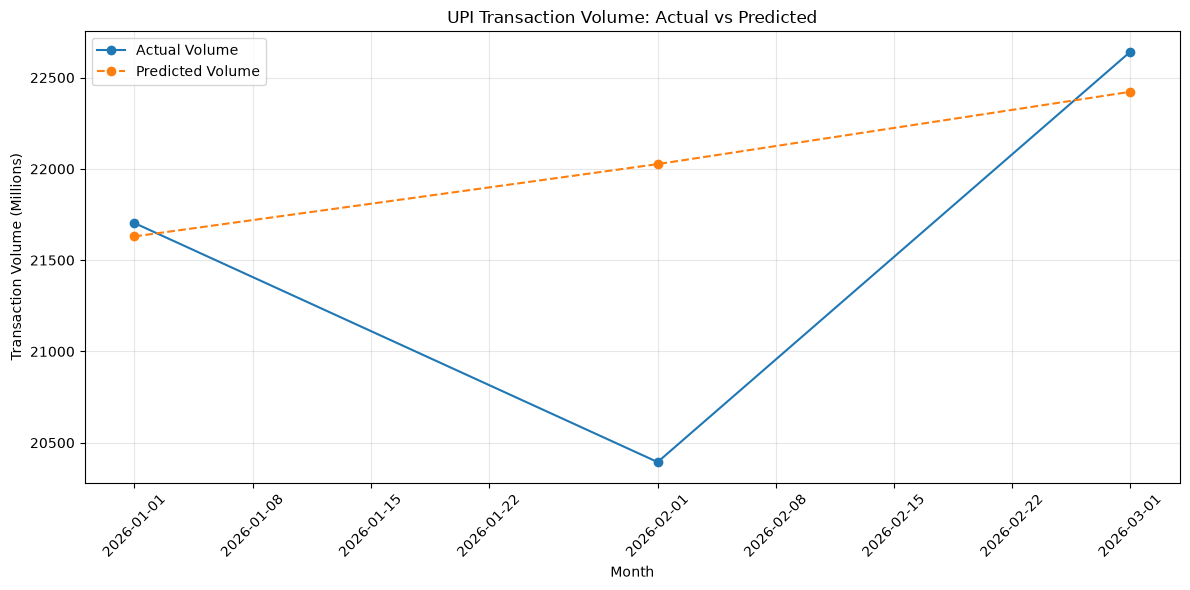

In [7]:
plt.figure(figsize=(12, 6))

plt.plot(
    df["Month"].iloc[21:],
    y_test,
    marker="o",
    label="Actual Volume"
)

plt.plot(
    df["Month"].iloc[21:],
    y_pred,
    marker="o",
    linestyle="--",
    label="Predicted Volume"
)

plt.title("UPI Transaction Volume: Actual vs Predicted")

plt.xlabel("Month")
plt.ylabel("Transaction Volume (Millions)")

plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# Select transaction value as our target

y_value = df["Value (In Cr.)"]

# Split training and testing data chronologically

y_value_train = y_value.iloc[:21]
y_value_test = y_value.iloc[21:]

# Create and train the model

value_model = LinearRegression()

value_model.fit(X_train, y_value_train)

# Make predictions

value_pred = value_model.predict(X_test)

# Compare actual and predicted values

value_results = pd.DataFrame({
    "Month": df["Month"].iloc[21:],
    "Actual Value (Cr.)": y_value_test.values,
    "Predicted Value (Cr.)": value_pred
})

value_results

,Month,Actual Value (Cr.),Predicted Value (Cr.)
21,2026-01-01,2833481.22,2.743534e+06
22,2026-02-01,2684229.29,2.780782e+06
23,2026-03-01,2952542.05,2.818030e+06


In [9]:
mae_value = mean_absolute_error(
    y_value_test, value_pred
)

rmse_value = np.sqrt(
    mean_squared_error(y_value_test, value_pred)
)

mape_value = np.mean(
    np.abs((y_value_test.values - value_pred) / y_value_test.values)
) * 100

print("MAE:", round(mae_value, 2))
print("RMSE:", round(rmse_value, 2))
print("MAPE:", round(mape_value, 2), "%")

MAE: 107004.05
RMSE: 108791.04
MAPE: 3.78 %


In [10]:
# Calculate quartiles

Q1 = df["Volume (In Mn.)"].quantile(0.25)
Q3 = df["Volume (In Mn.)"].quantile(0.75)

# Calculate IQR

IQR = Q3 - Q1

# Calculate anomaly boundaries

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify unusual observations

df["Volume Anomaly"] = np.where(
    (df["Volume (In Mn.)"] < lower_bound) |
    (df["Volume (In Mn.)"] > upper_bound),
    "Anomaly",
    "Normal"
)

# Display results

df[["Month", "Volume (In Mn.)", "Volume Anomaly"]]

,Month,Volume (In Mn.),Volume Anomaly
0,2024-04-01,13303.99,Normal
1,2024-05-01,14035.84,Normal
2,2024-06-01,13885.14,Normal
3,2024-07-01,14435.55,Normal
4,2024-08-01,14963.05,Normal
5,2024-09-01,15041.75,Normal
6,2024-10-01,16584.97,Normal
7,2024-11-01,15482.02,Normal
8,2024-12-01,16730.01,Normal
9,2025-01-01,16996.00,Normal


In [11]:
# Calculate quartiles

Q1_value = df["Value (In Cr.)"].quantile(0.25)
Q3_value = df["Value (In Cr.)"].quantile(0.75)

# Calculate IQR

IQR_value = Q3_value - Q1_value

# Calculate boundaries

lower_value = Q1_value - 1.5 * IQR_value
upper_value = Q3_value + 1.5 * IQR_value

# Identify anomalies

df["Value Anomaly"] = np.where(
    (df["Value (In Cr.)"] < lower_value) |
    (df["Value (In Cr.)"] > upper_value),
    "Anomaly",
    "Normal"
)

# Display results

df[["Month", "Value (In Cr.)", "Value Anomaly"]]

,Month,Value (In Cr.),Value Anomaly
0,2024-04-01,1964464.52,Normal
1,2024-05-01,2044937.05,Normal
2,2024-06-01,2007081.20,Normal
3,2024-07-01,2064292.41,Normal
4,2024-08-01,2060735.57,Normal
5,2024-09-01,2063994.71,Normal
6,2024-10-01,2349821.46,Normal
7,2024-11-01,2155187.40,Normal
8,2024-12-01,2324699.91,Normal
9,2025-01-01,2348037.12,Normal


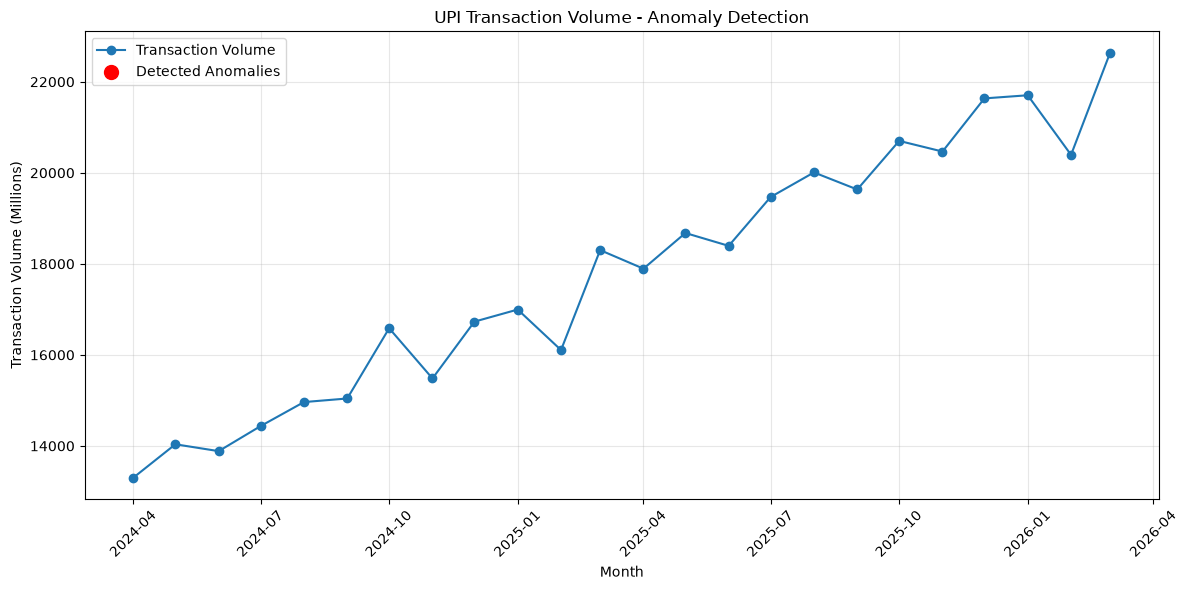

In [12]:
plt.figure(figsize=(12, 6))

normal = df[df["Volume Anomaly"] == "Normal"]
anomalies = df[df["Volume Anomaly"] == "Anomaly"]

plt.plot(
    df["Month"],
    df["Volume (In Mn.)"],
    label="Transaction Volume",
    marker="o"
)

plt.scatter(
    anomalies["Month"],
    anomalies["Volume (In Mn.)"],
    color="red",
    s=100,
    label="Detected Anomalies",
    zorder=5
)

plt.title("UPI Transaction Volume - Anomaly Detection")

plt.xlabel("Month")
plt.ylabel("Transaction Volume (Millions)")

plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
print("Total Months:", len(df))

print(
    "Volume Anomalies:",
    (df["Volume Anomaly"] == "Anomaly").sum()
)

print(
    "Value Anomalies:",
    (df["Value Anomaly"] == "Anomaly").sum()
)

Total Months: 24
Volume Anomalies: 0
Value Anomalies: 0


In [14]:
# Calculate monthly percentage changes

df["Volume Change (%)"] = (
    df["Volume (In Mn.)"].pct_change() * 100
)

df["Value Change (%)"] = (
    df["Value (In Cr.)"].pct_change() * 100
)

# Calculate average and standard deviation

volume_mean = df["Volume Change (%)"].mean()
volume_std = df["Volume Change (%)"].std()

value_mean = df["Value Change (%)"].mean()
value_std = df["Value Change (%)"].std()

# Identify unusual growth movements using 2 standard deviations

df["Volume Growth Anomaly"] = np.where(
    (df["Volume Change (%)"] > volume_mean + 2 * volume_std) |
    (df["Volume Change (%)"] < volume_mean - 2 * volume_std),
    "Unusual",
    "Normal"
)

df["Value Growth Anomaly"] = np.where(
    (df["Value Change (%)"] > value_mean + 2 * value_std) |
    (df["Value Change (%)"] < value_mean - 2 * value_std),
    "Unusual",
    "Normal"
)

# Display results

df[[
    "Month",
    "Volume Change (%)",
    "Volume Growth Anomaly",
    "Value Change (%)",
    "Value Growth Anomaly"
]]

,Month,Volume Change (%),Volume Growth Anomaly,Value Change (%),Value Growth Anomaly
0,2024-04-01,NaN,Normal,NaN,Normal
1,2024-05-01,5.500981,Normal,4.096410,Normal
2,2024-06-01,-1.073680,Normal,-1.851199,Normal
3,2024-07-01,3.964022,Normal,2.850468,Normal
4,2024-08-01,3.654173,Normal,-0.172303,Normal
5,2024-09-01,0.525962,Normal,0.158154,Normal
6,2024-10-01,10.259578,Normal,13.848231,Normal
7,2024-11-01,-6.650298,Normal,-8.282930,Normal
8,2024-12-01,8.060899,Normal,7.865326,Normal
9,2025-01-01,1.589897,Normal,1.003881,Normal


In [15]:
# Show months flagged as unusual in volume growth

volume_anomalies = df[
    df["Volume Growth Anomaly"] == "Unusual"
]

print("Unusual Volume Growth Months:")
display(volume_anomalies[[
    "Month",
    "Volume Change (%)"
]])

# Show months flagged as unusual in value growth

value_anomalies = df[
    df["Value Growth Anomaly"] == "Unusual"
]

print("Unusual Transaction Value Growth Months:")
display(value_anomalies[[
    "Month",
    "Value Change (%)"
]])

Unusual Volume Growth Months:


,Month,Volume Change (%)
11,2025-03-01,13.630287


Unusual Transaction Value Growth Months:


,Month,Value Change (%)


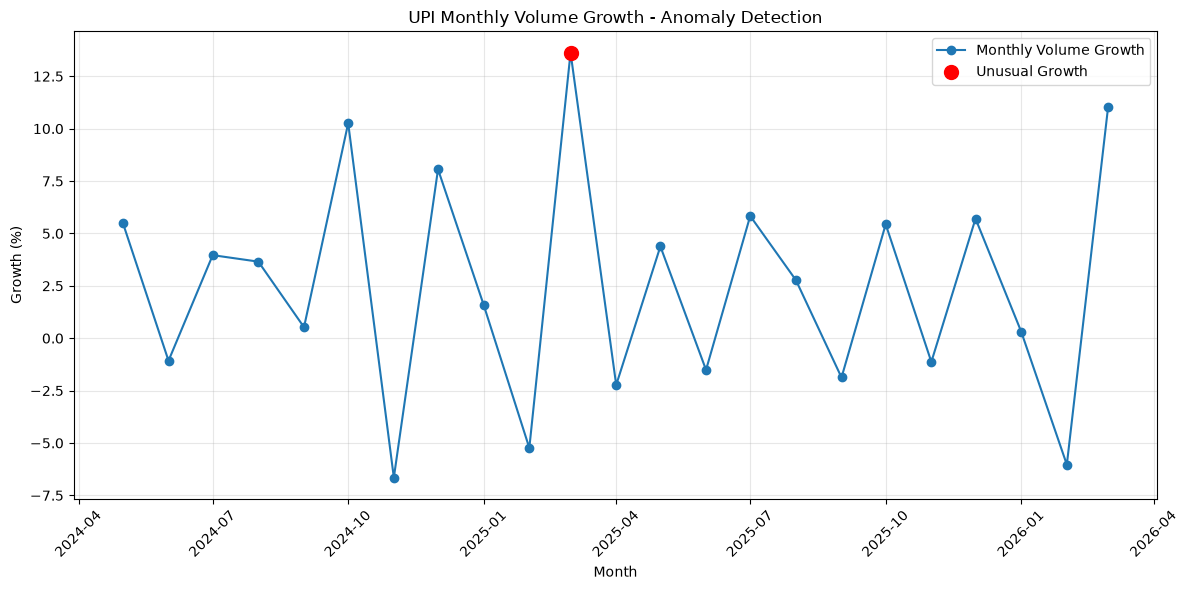

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(
    df["Month"],
    df["Volume Change (%)"],
    marker="o",
    label="Monthly Volume Growth"
)

plt.scatter(
    volume_anomalies["Month"],
    volume_anomalies["Volume Change (%)"],
    color="red",
    s=100,
    label="Unusual Growth",
    zorder=5
)

plt.title("UPI Monthly Volume Growth - Anomaly Detection")
plt.xlabel("Month")
plt.ylabel("Growth (%)")

plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

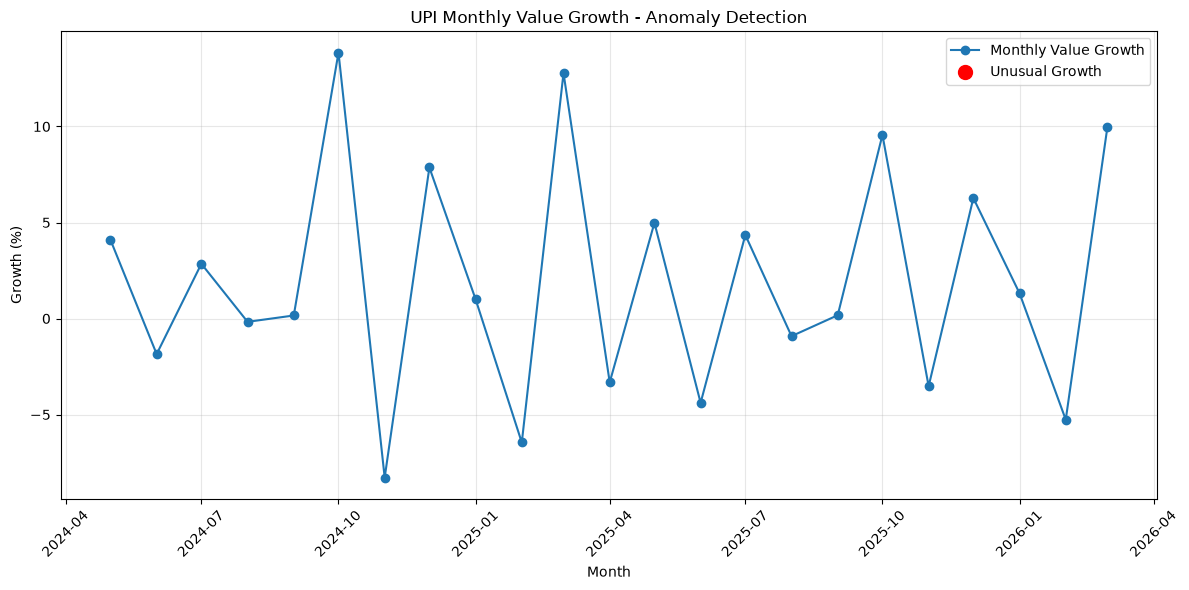

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(
    df["Month"],
    df["Value Change (%)"],
    marker="o",
    label="Monthly Value Growth"
)

plt.scatter(
    value_anomalies["Month"],
    value_anomalies["Value Change (%)"],
    color="red",
    s=100,
    label="Unusual Growth",
    zorder=5
)

plt.title("UPI Monthly Value Growth - Anomaly Detection")
plt.xlabel("Month")
plt.ylabel("Growth (%)")

plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Save the enhanced dataset with anomaly labels

df.to_csv(
    "../data/processed/upi_ml_results.csv",
    index=False
)

print("ML results saved successfully!")

ML results saved successfully!


In [19]:
# Create a combined forecasting results table

forecast_results = pd.DataFrame({
    "Month": df["Month"].iloc[21:].values,
    "Actual Volume (Mn.)": y_test.values,
    "Predicted Volume (Mn.)": y_pred,
    "Actual Value (Cr.)": y_value_test.values,
    "Predicted Value (Cr.)": value_pred
})

# Save forecasting results

forecast_results.to_csv(
    "../data/processed/upi_forecast_results.csv",
    index=False
)

print("Forecast results saved successfully!")

display(forecast_results)

Forecast results saved successfully!


,Month,Actual Volume (Mn.),Predicted Volume (Mn.),Actual Value (Cr.),Predicted Value (Cr.)
0,2026-01-01,21703.44,21630.100905,2833481.22,2.743534e+06
1,2026-02-01,20394.18,22026.152632,2684229.29,2.780782e+06
2,2026-03-01,22641.11,22422.204359,2952542.05,2.818030e+06
